<div style="background:linear-gradient(90deg,#7a4a1e,#c58b3a);padding:26px;border-radius:14px;color:white">
<h4 style="margin:0;opacity:0.9">🧬 AI GENESIS · THE STORY OF AI, ONE ALGORITHM AT A TIME</h4>
<h1 style="margin:6px 0 4px 0">Mechanical Calculators (1642 to 1673)</h1>
<p style="margin:0">Pascal's <b>Pascaline</b> and Leibniz's <b>Stepped Reckoner</b>: the first machines that did arithmetic.</p>
</div>

<br>

| 🪪 Quick card | |
|---|---|
| **Years** | 1642 (Pascaline) and 1673 (Stepped Reckoner) |
| **Inventors** | Blaise Pascal (France) and Gottfried Wilhelm Leibniz (Germany) |
| **Family** | Computing history → machines that run an algorithm |
| **Learns from data?** | ❌ No. They follow fixed mechanical rules |
| **Before them** | Abacus, Napier's bones (1617), slide rule (1622), Schickard's calculating clock (1623) |
| **Leads to** | Babbage's engines (1820s to 1830s), Lovelace's program (1843), the modern CPU |
| **Difficulty** | ⭐ Beginner |

### 🎯 What you will learn in this notebook
1. How a machine can **add** with gears, and how a **carry** travels from wheel to wheel
2. How Pascal made a machine **subtract** without a "minus" gear (the *nines' complement* trick)
3. How Leibniz made a machine **multiply and divide** (repeated addition with a **shifting carriage**)
4. Why these old ideas are still **inside every modern processor**
5. What these machines could **not** do, which is the reason programmable computers were invented

## 📖 Part 1: The story

### 👦 Pascal and the tax machine (1642)
**Blaise Pascal** was a teenage prodigy in France. His father collected taxes in Rouen and spent his evenings adding long columns of numbers. To help him, Pascal built a **mechanical adding machine** in **1642**, later called the **Pascaline**.

- It had a row of **dials**, each showing a digit **0 to 9**, connected by gears.
- When one dial passed 9 and went back to 0, a clever mechanism pushed the next dial forward by one. That is a **carry**.
- Pascal built about **fifty** machines over the next ten years. He proved that **arithmetic can be done by matter, not just by a mind**.

> 📝 An earlier calculator was designed by **Wilhelm Schickard** in **1623**, known from his letters to the astronomer Kepler. But Pascal's machine was the first to become well known and widely copied.

### ⚙️ Leibniz and the Stepped Reckoner (1673)
**Gottfried Leibniz** (who also invented calculus) wanted more than addition. In **1673** he showed the Royal Society in London the **Stepped Reckoner**, which could also **multiply and divide** automatically.

His key invention was the **stepped drum**, a cylinder with nine teeth of **different lengths**. By sliding a gear along the drum, the machine could add any digit from 1 to 9 with one turn of the crank.

Leibniz felt it was a waste of great minds to spend hours on dull calculation. Machines, he argued, should do that work.

### 🌱 Why this matters for AI
- It showed that a **procedure** (an algorithm) can be **carried out by a mechanism**.
- Leibniz went on to dream of a universal **language of reasoning**, plus the **binary system** (next notebooks).
- About 150 years later, Charles Babbage would add the missing piece: **programmability**.

### 🗺️ Where this fits
```
Al-Khwarizmi: algorithms (820) → Pascaline (1642) → Stepped Reckoner (1673) → Leibniz: binary (1703) → Babbage (1830s) → Lovelace (1843)
```

## 🧠 Part 2: The ideas in plain words

### 1. Adding with wheels
Each wheel stores **one digit**. Adding a digit means turning the wheel forward by that many steps. If it passes 9, it wraps to 0 and **nudges the next wheel by 1**: the **carry**. A carry can trigger *another* carry, a chain reaction, like `9999 + 1`.

### 2. Subtracting without a "minus" gear: the nines' complement
The Pascaline's wheels only turn **forward**. So Pascal turned subtraction into addition:

> To compute `a − b` with `n` wheels:
> 1. Replace every digit of `b` by `9 − digit` (this is the **nines' complement**).
> 2. **Add** it to `a`.
> 3. If a number spilled past the top wheel, drop it and **add 1** (the *end-around carry*). That is the answer.
> 4. If nothing spilled, the answer is **negative**: take the complement of what you see.

Example with 3 wheels: `827 − 349` → complement of 349 is `650` → `827 + 650 = 1477` → drop the leading 1 and add 1 → **478**. ✅

### 3. Multiplying by repeating
Leibniz's machine multiplies like we do on paper: `427 × 36` means *"add 427, six times, then shift one place left and add 427 three more times"*. The **shifting carriage** moves the number one place to the left, which is exactly multiplying by 10.

### 4. Dividing by repeating
Division is the reverse: **subtract** the divisor again and again (shifting as needed) and count how many times it fits.

> 💡 *Shift and add* is **still how computers multiply today**, only in binary.

## 🟣 Step 1: Import the libraries
> 💡 Standard tools: `random` for test numbers, plus `pandas`, `numpy` and `matplotlib`.

In [1]:
# Import the libraries we need
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch, Rectangle

# Styling and a colour palette used across the notebook
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BRONZE, GOLD, GREEN, ORANGE, RED, BLUE, PURPLE, GREY, DARK = "#7a4a1e", "#d4a73a", "#27ae60", "#f39c12", "#e74c3c", "#4286f4", "#8e54e9", "#bdc3c7", "#2c3e50"

print("✅ Libraries ready!")

✅ Libraries ready!


## 🖼️ Step 2: A timeline of calculating machines
> 💡 People have always built tools to help with arithmetic. This timeline shows where the two machines of this notebook sit. The ones in colour are the stars of today.

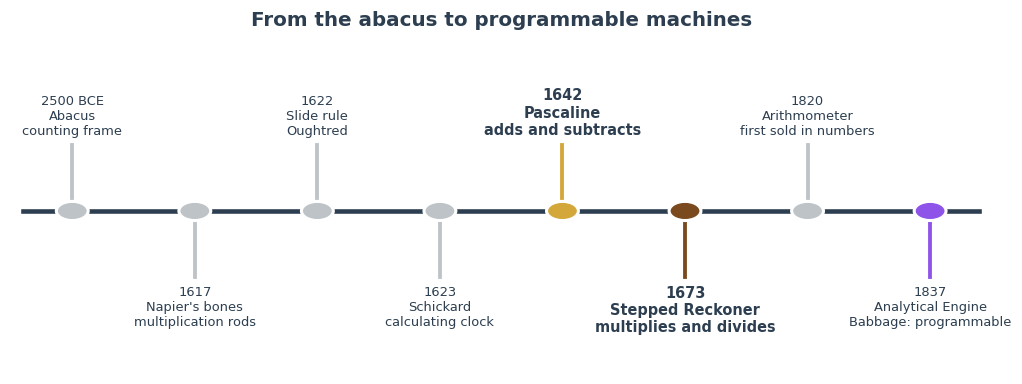

In [2]:
# Timeline of calculating devices
events = [(-2500, "Abacus", "counting frame", GREY, False),
          (1617, "Napier's bones", "multiplication rods", GREY, False),
          (1622, "Slide rule", "Oughtred", GREY, False),
          (1623, "Schickard", "calculating clock", GREY, False),
          (1642, "Pascaline", "adds and subtracts", GOLD, True),
          (1673, "Stepped Reckoner", "multiplies and divides", BRONZE, True),
          (1820, "Arithmometer", "first sold in numbers", GREY, False),
          (1837, "Analytical Engine", "Babbage: programmable", PURPLE, False)]

fig, ax = plt.subplots(figsize=(11.5, 4))
ax.set_xlim(-0.5, len(events) - 0.5); ax.set_ylim(-2.2, 2.4); ax.axis("off")
ax.plot([-0.4, len(events) - 0.6], [0, 0], color=DARK, lw=3, zorder=1)
for i, (year, name, note, color, star) in enumerate(events):
    up = (i % 2 == 0)
    ax.plot([i, i], [0, 0.9 if up else -0.9], color=color, lw=2.5, zorder=1)
    ax.add_patch(Circle((i, 0), 0.13, color=color, ec="white", lw=2, zorder=3))
    label_year = f"{abs(year)} BCE" if year < 0 else str(year)
    y = 1.0 if up else -1.0
    va = "bottom" if up else "top"
    ax.text(i, y, f"{label_year}\n{name}\n{note}", ha="center", va=va, fontsize=8.5 if not star else 9.5,
            color=DARK, fontweight="bold" if star else None)
ax.set_title("From the abacus to programmable machines", color=DARK, fontweight="bold", fontsize=13)
plt.show()

## ⚙️ Step 3: Build a Pascaline in code
> 💡 We simulate the dials. Each wheel holds a digit 0 to 9. `dial(wheel, digit)` turns one wheel forward and **spreads carries** to the left, writing down every carry in a log. If a carry falls off the top wheel, we raise an **overflow** flag.

In [3]:
# A Pascaline: a row of wheels with carry propagation
class Pascaline:
    def __init__(self, wheels=6):
        self.wheels = [0] * wheels             # wheel 0 is the units wheel
        self.carry_log = []                    # which wheels produced a carry
        self.overflow = False                  # did a carry fall off the top wheel?

    def dial(self, wheel, digit):
        '''Turn one wheel forward by `digit` steps and let the carries ripple to the left.'''
        self.wheels[wheel] += digit
        k = wheel
        while self.wheels[k] >= 10:            # the wheel passed 9 and wrapped to 0: carry!
            self.wheels[k] -= 10
            self.carry_log.append(k)
            if k + 1 < len(self.wheels):
                self.wheels[k + 1] += 1        # nudge the next wheel
            else:
                self.overflow = True           # the carry fell off the top wheel
                break
            k += 1

    def add(self, number):
        '''Dial the number one digit at a time, starting from the units wheel.'''
        for position, d in enumerate(reversed(str(number))):
            self.dial(position, int(d))

    def value(self):
        return int("".join(str(d) for d in reversed(self.wheels)))

p = Pascaline(wheels=6)
p.add(4999)
print("Register shows:", p.value())
p.carry_log.clear()
p.add(1)
print("After adding 1:", p.value(), "| carries triggered:", len(p.carry_log), "→ wheels", p.carry_log)

Register shows: 4999
After adding 1: 5000 | carries triggered: 3 → wheels [0, 1, 2]


## 🔢 Step 4: See the carry chain
> 💡 Adding `1` to `4999` makes **three** wheels flip in a row. The picture shows each wheel before and after. Brown wheels are the ones that moved.

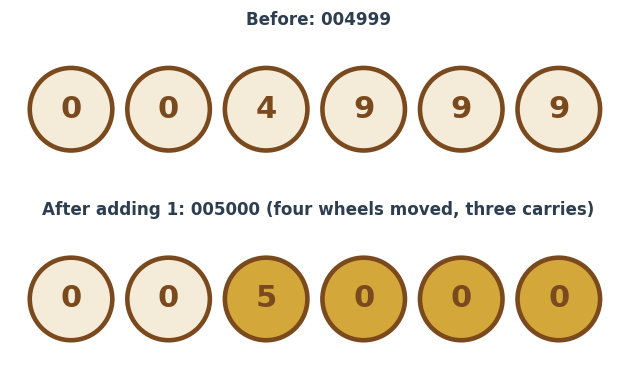

In [4]:
# Draw the register before and after adding 1 to 4999
def draw_register(ax, values, changed, title):
    n = len(values)
    for i, d in enumerate(reversed(values)):             # most significant wheel on the left
        wheel_index = n - 1 - i
        face = GOLD if wheel_index in changed else "#f4ecd8"
        ax.add_patch(Circle((i * 1.3, 0), 0.55, fc=face, ec=BRONZE, lw=3))
        ax.text(i * 1.3, 0, str(d), ha="center", va="center", fontsize=20, fontweight="bold", color=BRONZE)
    ax.set_xlim(-0.8, n * 1.3 - 0.4); ax.set_ylim(-1, 1); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, color=DARK, fontweight="bold", fontsize=11)

before = Pascaline(6); before.add(4999)
after = Pascaline(6); after.add(4999); after.carry_log.clear(); after.add(1)
changed = {i for i, (x, y) in enumerate(zip(before.wheels, after.wheels)) if x != y}

fig, axes = plt.subplots(2, 1, figsize=(7.5, 3.6))
draw_register(axes[0], before.wheels, set(), "Before: 004999")
draw_register(axes[1], after.wheels, changed, "After adding 1: 005000 (four wheels moved, three carries)")
plt.tight_layout()
plt.show()

## ✅ Step 5: Does our machine add correctly?
> 💡 Always **test**. We ask the Pascaline to add 2,000 random pairs of numbers and compare with Python's own addition.

In [5]:
# Test the Pascaline against Python's addition on random numbers
rng = random.Random(42)
tests, wrong = 2000, 0
for _ in range(tests):
    a, b = rng.randrange(0, 400_000), rng.randrange(0, 400_000)
    m = Pascaline(wheels=6)
    m.add(a); m.add(b)
    if m.value() != a + b:
        wrong += 1
print(f"Additions tested: {tests:,} | wrong answers: {wrong}")
assert wrong == 0
print("✅ The mechanical adder agrees with arithmetic.")

Additions tested: 2,000 | wrong answers: 0
✅ The mechanical adder agrees with arithmetic.


## ➖ Step 6: Subtraction by adding (the nines' complement)
> 💡 The wheels only turn forward, so Pascal turned subtraction into addition. We follow the four steps from Part 2 using our Pascaline and print every stage for `827 − 349`.

In [6]:
# Subtraction on a machine that can only add
def nines_complement(number, wheels):
    return int("".join(str(9 - int(d)) for d in str(number).zfill(wheels)))

def subtract(a, b, wheels=6, verbose=False):
    complement = nines_complement(b, wheels)
    m = Pascaline(wheels)
    m.add(a); m.add(complement)
    shown = m.value()
    if m.overflow:                                   # a carry fell off the top: add 1 back (end-around carry)
        result = shown + 1
        how = "a number spilled over the top wheel, so add 1 back"
    else:                                            # nothing spilled: the answer is negative
        result = -nines_complement(shown, wheels)
        how = "nothing spilled, so the answer is negative: take the complement of what you see"
    if verbose:
        print(f"{a} − {b}")
        print(f"  1) nines' complement of {b} (with {wheels} wheels): {complement:0{wheels}d}")
        print(f"  2) add it to {a}: the wheels show {shown:0{wheels}d}")
        print(f"  3) {how}")
        print(f"  → result: {result}")
    return result

subtract(827, 349, verbose=True)
print()
subtract(349, 827, verbose=True)

rng = random.Random(1)
for _ in range(2000):
    a, b = rng.randrange(0, 400_000), rng.randrange(0, 400_000)
    assert subtract(a, b) == a - b
print("\n✅ 2,000 random subtractions checked: the adding-only machine subtracts correctly.")

827 − 349
  1) nines' complement of 349 (with 6 wheels): 999650
  2) add it to 827: the wheels show 000477
  3) a number spilled over the top wheel, so add 1 back
  → result: 478

349 − 827
  1) nines' complement of 827 (with 6 wheels): 999172
  2) add it to 349: the wheels show 999521
  3) nothing spilled, so the answer is negative: take the complement of what you see
  → result: -478

✅ 2,000 random subtractions checked: the adding-only machine subtracts correctly.


## ⚙️ Step 7: Leibniz's stepped drum
> 💡 The secret of the Stepped Reckoner is a cylinder with **nine teeth of lengths 1 to 9**, side by side. A small gear slides along it. The further the gear sits to one end, the **more teeth** it touches, so one turn of the crank moves it by that many tenths of a turn.
> So **the position of the gear selects the digit** to add. The picture shows how many teeth each gear position meets.

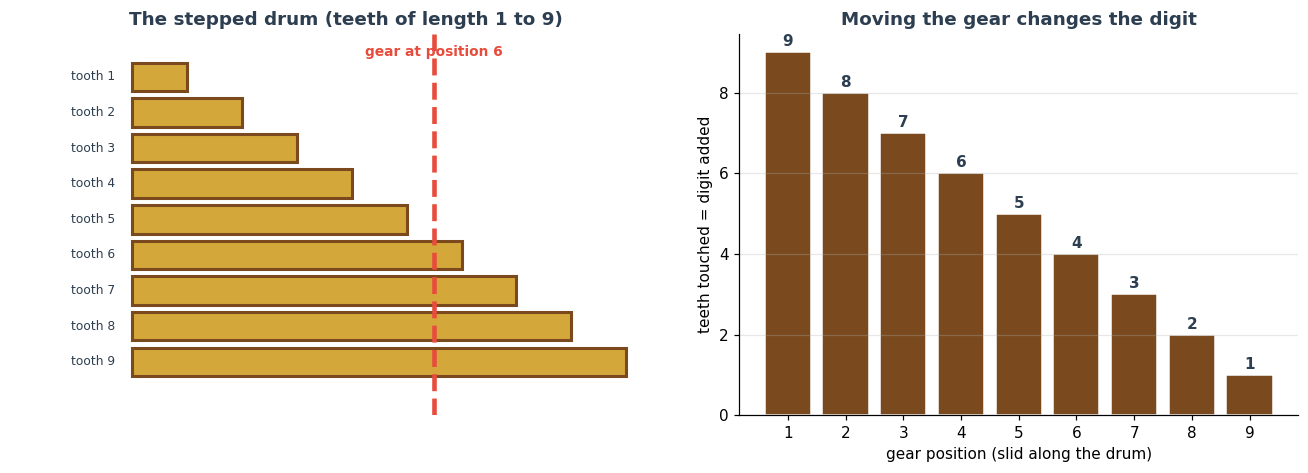

In [7]:
# Draw the stepped drum and count the teeth the sliding gear meets at each position
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.2, 1]})

for tooth in range(1, 10):                                  # tooth `k` reaches positions 1..k
    ax1.add_patch(Rectangle((0, 10 - tooth - 0.4), tooth, 0.8, fc=GOLD, ec=BRONZE, lw=2))
    ax1.text(-0.3, 10 - tooth, f"tooth {tooth}", ha="right", va="center", fontsize=8, color=DARK)
position = 6
ax1.axvline(position - 0.5, color=RED, lw=3, ls="--")
ax1.text(position - 0.5, 9.6, f"gear at position {position}", color=RED, ha="center", fontsize=9, fontweight="bold")
ax1.set_xlim(-2.2, 10); ax1.set_ylim(-0.5, 10.2); ax1.axis("off")
ax1.set_title("The stepped drum (teeth of length 1 to 9)", color=DARK, fontweight="bold")

positions = np.arange(1, 10)
engaged = [sum(1 for tooth in range(1, 10) if tooth >= p) for p in positions]    # teeth long enough to reach this position
bars = ax2.bar(positions, engaged, color=BRONZE, edgecolor="white")
for p, e in zip(positions, engaged):
    ax2.text(p, e + 0.15, str(e), ha="center", fontweight="bold", color=DARK)
ax2.set_xlabel("gear position (slid along the drum)"); ax2.set_ylabel("teeth touched = digit added")
ax2.set_title("Moving the gear changes the digit", color=DARK, fontweight="bold")
ax2.set_xticks(positions); ax2.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## ✖️ Step 8: Multiplication and division, the Leibniz way
> 💡 We write the **Stepped Reckoner** as code.
> - `multiply(a, b)`: for each digit of `b` (from the right), turn the crank *that many times*, then **shift the carriage** one place.
> - `divide(a, b)`: for each place from the left, **subtract** the shifted divisor while it fits, counting the cranks.
> The table shows each stage for `427 × 36`.

In [8]:
# The Stepped Reckoner: multiplication = repeated addition with shifts, division = repeated subtraction with shifts
class SteppedReckoner:
    def multiply(self, a, b):
        accumulator, rows, cranks = 0, [], 0
        for place, ch in enumerate(reversed(str(b))):             # units digit of b first
            digit = int(ch)
            for _ in range(digit):
                accumulator += a * 10 ** place                    # the carriage is shifted `place` positions
                cranks += 1
            rows.append({"digit of multiplier": digit, "carriage shift": place,
                         "cranks": digit, "accumulator": accumulator})
        return accumulator, pd.DataFrame(rows), cranks

    def divide(self, a, b):
        remainder, quotient, rows, cranks = a, 0, [], 0
        for place in range(len(str(a)) - len(str(b)), -1, -1):    # from the biggest place down
            times = 0
            while remainder >= b * 10 ** place:
                remainder -= b * 10 ** place
                times += 1; cranks += 1
            quotient += times * 10 ** place
            rows.append({"carriage shift": place, "times it fits": times, "remainder left": remainder})
        return quotient, remainder, pd.DataFrame(rows), cranks

machine = SteppedReckoner()
product, steps, cranks = machine.multiply(427, 36)
assert product == 427 * 36
print(f"427 × 36 = {product}  (cranks turned: {cranks})")
print(steps.to_string(index=False))

q, r, div_steps, div_cranks = machine.divide(15372, 36)
assert (q, r) == divmod(15372, 36)
print(f"\n15372 ÷ 36 = {q} remainder {r}  (cranks turned: {div_cranks})")
print(div_steps.to_string(index=False))

rng = random.Random(3)
for _ in range(1000):
    x, y = rng.randrange(1, 5000), rng.randrange(1, 500)
    assert machine.multiply(x, y)[0] == x * y
    assert machine.divide(x, y)[:2] == divmod(x, y)
print("\n✅ 1,000 random multiplications and divisions checked.")

427 × 36 = 15372  (cranks turned: 9)
 digit of multiplier  carriage shift  cranks  accumulator
                   6               0       6         2562
                   3               1       3        15372

15372 ÷ 36 = 427 remainder 0  (cranks turned: 13)
 carriage shift  times it fits  remainder left
              3              0           15372
              2              4             972
              1              2             252
              0              7               0

✅ 1,000 random multiplications and divisions checked.


## 💻 Step 9: The same idea inside your computer
> 💡 Change the **base** from 10 to **2** and Leibniz's method becomes how a modern processor multiplies: for each bit of the multiplier, **add the shifted number if the bit is 1**. In binary, a digit is only 0 or 1, so each place needs **at most one** addition instead of up to nine.
> We compare the number of "cranks" (additions) in both systems on 500 random multiplications of 3-digit numbers.

In [9]:
# Shift-and-add in binary, and a crank count comparison
def shift_and_add(a, b):
    accumulator, rows, additions = 0, [], 0
    for place, bit in enumerate(reversed(bin(b)[2:])):
        if bit == "1":
            accumulator += a << place                            # shift left = multiply by 2^place
            additions += 1
        rows.append({"bit of multiplier": int(bit), "shift": place,
                     "add shifted a?": "yes" if bit == "1" else "no", "accumulator": accumulator})
    return accumulator, pd.DataFrame(rows), additions

product, rows, adds = shift_and_add(13, 11)
assert product == 143
print(f"13 × 11 (11 in binary is {bin(11)[2:]}) = {product}, additions needed: {adds}")
print(rows.to_string(index=False))

rng = random.Random(8)
pairs = [(rng.randrange(100, 1000), rng.randrange(100, 1000)) for _ in range(500)]
decimal_cranks = np.mean([sum(int(d) for d in str(b)) for _, b in pairs])
binary_adds = np.mean([bin(b).count("1") for _, b in pairs])
print(f"\nAverage additions per multiplication (3-digit numbers):")
print(f"  decimal, Leibniz style: {decimal_cranks:.1f}")
print(f"  binary, shift-and-add:  {binary_adds:.1f}")

13 × 11 (11 in binary is 1011) = 143, additions needed: 3
 bit of multiplier  shift add shifted a?  accumulator
                 1      0            yes           13
                 1      1            yes           39
                 0      2             no           39
                 1      3            yes          143

Average additions per multiplication (3-digit numbers):
  decimal, Leibniz style: 14.1
  binary, shift-and-add:  5.2


## ⛓️ Step 10: The weakness of a long carry
> 💡 In a real Pascaline, a carry had to travel through the gears **one wheel at a time**, pushing against friction. Long chains were a real problem, and they were a famous weak point in Leibniz's machine too. Our code can count how long the chain gets for different numbers.

     register  wheels  carries in one go   result
       99 + 1       3                  2      100
      999 + 1       4                  3     1000
    9,999 + 1       5                  4    10000
   99,999 + 1       6                  5   100000
9,999,999 + 1       8                  7 10000000


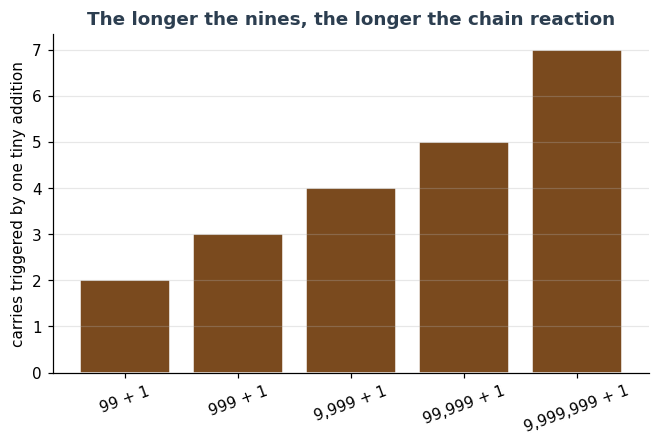

In [10]:
# How long can a carry chain be?
rows = []
for wheels, number in [(3, 99), (4, 999), (5, 9999), (6, 99999), (8, 9999999)]:
    m = Pascaline(wheels)
    m.add(number)
    m.carry_log.clear()
    m.add(1)
    rows.append({"register": f"{number:,} + 1", "wheels": wheels, "carries in one go": len(m.carry_log),
                 "result": m.value() if not m.overflow else "overflow past the top wheel"})
chain = pd.DataFrame(rows)
print(chain.to_string(index=False))

plt.figure(figsize=(7, 4))
plt.bar(chain["register"], chain["carries in one go"], color=BRONZE, edgecolor="white")
plt.ylabel("carries triggered by one tiny addition"); plt.xticks(rotation=20)
plt.title("The longer the nines, the longer the chain reaction", color=DARK, fontweight="bold")
plt.grid(axis="y", alpha=0.3)
plt.show()

## ⚠️ Limitations of the mechanical calculators

| Limitation | What it means | Who fixed it |
|---|---|---|
| ❌ **No program** | Every step needed a human to set dials and turn the crank. The machine could not follow a *list* of instructions | Babbage's Analytical Engine (1837), Lovelace's program (1843) |
| ❌ **No memory of its own plan** | It remembered numbers, but not *what to do next* | Stored-program computers (1940s) |
| ❌ **Fragile mechanics** | Long carries, friction and tiny gear errors broke the machines | Better engineering, then electronics |
| ❌ **Arithmetic only** | It could not compare, decide or repeat | Conditional jumps and loops in programs |
| ❌ **Very expensive** | Each machine was hand-made | Mass production (the Arithmometer, 1820) |

### 🧬 What they gave us
- The proof that **calculation can be mechanised**
- Techniques still in every processor today: **carry propagation, complement arithmetic and shift-and-add**
- The dream that machines might also do **reasoning**, which led straight to Leibniz's later ideas

## 📝 Summary
1. ✅ The **Pascaline** (1642) added with wheels, and a carry **rippled** from wheel to wheel.
2. ✅ It **subtracted** by adding the **nines' complement**, then fixing the result with an end-around carry.
3. ✅ Leibniz's **Stepped Reckoner** (1673) used a **stepped drum** and a **shifting carriage** to multiply and divide.
4. ✅ Multiplication = **repeated addition with shifts**. In binary this is exactly what processors still do.
5. ✅ These machines followed **fixed** procedures. The next big step was a machine that follows a **program**.

## 🧪 Practice time
**Exercise 1.** Compute `500 − 237` with `subtract(500, 237, wheels=3, verbose=True)`. Explain each line.

**Exercise 2.** Multiply `123 × 45` with the Stepped Reckoner. How many cranks does it need? How many would binary shift-and-add need for the same numbers?

**Exercise 3.** How many carries happen when you add 1 to `99999` on a 6-wheel Pascaline?

<details>
<summary>👀 Click to see the solutions</summary>

```python
# Exercise 1
print(subtract(500, 237, wheels=3, verbose=True))      # 263

# Exercise 2
product, _, cranks = SteppedReckoner().multiply(123, 45)
print(product, cranks)                                 # 5535 with 9 cranks (5 + 4)
print(shift_and_add(123, 45)[2])                       # 4 additions (45 = 101101 has four 1-bits)

# Exercise 3
m = Pascaline(6); m.add(99999); m.carry_log.clear(); m.add(1)
print(len(m.carry_log), m.value())                     # 5 carries, result 100000
```
</details>

## ⏭️ What's next in AI-Genesis
Next stop on the road: **Probability Theory (Pascal and Fermat, 1654)**, the letters about a gambling problem that created the mathematics of uncertainty. (Yes, Pascal again.) 🚀